# Classification des tokens par famille économique

**Question :** quels tokens des transferts tracés peuvent être rattachés à ETH, BTC,
USD ou à une autre référence ? Cette étape prépare l'étude des expositions.

On construit une table de correspondance **une adresse de contrat → une famille**.
Ce n'est pas un apprentissage statistique : les règles et les sources sont explicites.
La famille n'est ni un prix, ni une quantité, ni une preuve de stratégie long/short.

Le fichier provient du pipeline du groupe décrit dans `README_FILTERING.md` :
transferts des wallets Aave V3 Ethereum conservés par le traçage, de janvier 2023
à mai 2026. Une ligne décrit un transfert vu par un wallet, pas un emprunt ni une
personne. Un transfert entre deux wallets peut figurer dans leurs deux historiques.

**Avant d'exécuter :** installer l'environnement de `README_CLASSIFICATION.md` et placer le Parquet
déjà disponible en local dans `data/transfers_wallets_traced.parquet`.
Puis redémarrer le noyau et exécuter toutes les cellules. Aucun téléchargement
ni contrôle de version du fichier n'est effectué.

Ce notebook appelle les cinq fonctions définies dans `scripts/token_families.py`.
Les fichiers JSON fournissent les correspondances utilisées par ces fonctions.
On exécute le notebook ; on n'a pas besoin de lancer le fichier `.py` séparément.


In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq

# Le notebook se trouve dans le dossier "statistiques descriptives" du dépôt.
ROOT = Path.cwd()
if ROOT.name == "classification":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "scripts"))
from token_families import (
    classify_tokens, classify_transfers, family_summary, propose_family, token_inventory,
)

DATA = ROOT / "data"
INPUT = DATA / "transfers_wallets_traced.parquet"
OUTPUT = DATA / "transfers_wallets_classified.parquet"
REF = DATA / "reference"

## 1. Lire le fichier et regarder les colonnes

On suppose que le fichier local est fixe.
On le lit directement, sans contrôle de version. Les limites
de la collecte sont décrites dans `README_FILTERING.md`.

`token_address` identifie le contrat sur Ethereum. `token_symbol` est son sigle,
qui peut être partagé par plusieurs contrats. `value` est un entier stocké en texte :
la quantité en tokens vaut `int(value) / 10**token_decimal`.
Nous ne sommons pas les quantités de tokens différents.

`tracked=True` indique une transaction du wallet comprenant un événement Aave.
`traced_fraction` est la fraction attribuée aux fonds tracés par l'algorithme du groupe.
Ces deux colonnes ne mesurent pas une exposition économique.

Cette analyse part du fichier intermédiaire déjà préparé par le groupe.
La collecte et le traçage ont lieu en amont ; aucune cellule ne les relance.

WETH signifie *Wrapped Ether* : c'est une représentation d'ETH au format ERC-20.
Le mécanisme de conversion permet de déposer 1 ETH contre 1 WETH et de faire
l'opération inverse. [Présentation sur ethereum.org](https://ethereum.org/wrapped-eth/).
Dans ce fichier, l'ETH natif a déjà été rangé sous l'adresse WETH par le pipeline du groupe.
Ce choix ne signifie pas que tous les tokens dont le nom contient ETH sont identiques.


In [2]:
parquet = pq.ParquetFile(INPUT)
display(pd.DataFrame({
    "colonne": parquet.schema_arrow.names,
    "type": [str(field.type) for field in parquet.schema_arrow],
}))
preview = next(parquet.iter_batches(batch_size=8, columns=[
    "timestamp", "token_symbol", "token_name", "token_address", "value", "token_decimal",
    "tracked", "traced_fraction",
])).to_pandas()
preview["date"] = pd.to_datetime(preview["timestamp"], unit="s", utc=True)
display(preview.drop(columns="timestamp"))

,colonne,type
0,user,string
1,block_number,int64
2,timestamp,int64
3,tx_hash,string
4,from,string
5,to,string
6,token_address,string
7,token_symbol,string
8,token_name,string
9,token_decimal,int64


,token_symbol,token_name,token_address,value,token_decimal,tracked,traced_fraction,date
0,aEthWETH,Aave Ethereum WETH,0x4d5f47fa6a74757f35c14fd3a6ef8e3c9bc514e8,280679999999999999999,18,True,1.000000,2026-04-01 10:47:47+00:00
1,ETH,Ether,0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2,280680000000000000000,18,True,1.000000,2026-04-01 10:47:47+00:00
2,aEthWETH,Aave Ethereum WETH,0x4d5f47fa6a74757f35c14fd3a6ef8e3c9bc514e8,144756917947090285,18,False,0.999485,2026-04-12 11:13:47+00:00
3,aEthWETH,Aave Ethereum WETH,0x4d5f47fa6a74757f35c14fd3a6ef8e3c9bc514e8,280824756917947090284,18,False,0.999485,2026-04-12 11:13:47+00:00
4,ETH,Ether,0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2,280824756917947090284,18,False,0.999485,2026-04-12 11:13:47+00:00
5,wstETH,Wrapped liquid staked Ether 2.0,0x7f39c581f595b53c5cb19bd0b3f8da6c935e2ca0,227991825659069697488,18,False,0.999501,2026-04-12 11:15:59+00:00
6,ETH,Ether,0xC02aaA39b223FE8D0A0e5C4F27eAD9083C756Cc2,280820000000000000000,18,False,0.999501,2026-04-12 11:15:59+00:00
7,wstETH,Wrapped liquid staked Ether 2.0,0x7f39c581f595b53c5cb19bd0b3f8da6c935e2ca0,227991825659069697488,18,False,0.999501,2026-04-18 22:15:11+00:00


## 2. Passer des transferts à un inventaire de tokens

On lit le fichier par lots de 250 000 lignes avec PyArrow, puis on utilise les
`groupby` de pandas pour compter les observations. Le classement ne travaille
ensuite que sur cet inventaire, beaucoup plus petit.

On met les adresses en minuscules pour la jointure. On garde les symboles manquants,
les transferts de valeur nulle et les contrats inconnus dans les dénominateurs :
les enlever améliorerait artificiellement la couverture. On conserve aussi les
variantes de symbole et on signale les métadonnées contradictoires.


In [3]:
inventory = token_inventory(INPUT)
display(inventory[["token_symbol", "token_address", "symbols", "n_rows", "n_tracked"]].head(15)) 

,token_symbol,token_address,symbols,n_rows,n_tracked
0,USDC,0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48,[USDC],1320053,573520
1,ETH,0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2,"[ETH, WETH]",1298754,422160
2,USDT,0xdac17f958d2ee523a2206206994597c13d831ec7,[USDT],1088001,507640
3,aEthWETH,0x4d5f47fa6a74757f35c14fd3a6ef8e3c9bc514e8,[aEthWETH],769328,459710
4,variableDebtEthUSDT,0x6df1c1e379bc5a00a7b4c6e67a203333772f45a8,[variableDebtEthUSDT],379964,379964
5,aEthUSDC,0x98c23e9d8f34fefb1b7bd6a91b7ff122f4e16f5c,[aEthUSDC],374221,316832
6,variableDebtEthUSDC,0x72e95b8931767c79ba4eee721354d6e99a61d004,[variableDebtEthUSDC],369067,369067
7,WBTC,0x2260fac5e5542a773aa44fbcfedf7c193bc2c599,[WBTC],336180,177988
8,aEthUSDT,0x23878914efe38d27c4d67ab83ed1b93a74d4086a,[aEthUSDT],288809,236988
9,aEthWBTC,0x5ee5bf7ae06d1be5997a1a72006fe6c607ec6de8,[aEthWBTC],228701,207927


## 3. Rendre les règles lisibles

Deux références sont versionnées dans Git :

- `symbol_aliases.json` associe 240 sigles à une famille : DAI → USD, sENA → ENA,
  STONE → ETH, stLINK → LINK. Il contient aussi le type et des notes ; les nouveaux
  alias de staking sont accompagnés de leur source.
- `token_reference.json` associe 448 **adresses** à une famille, un type et des
  sources, à partir des registres Aave/Uniswap et de décisions documentées.

On utilise d'abord la correspondance par adresse (`status = reference_match`).
Si elle manque, **on accepte la famille proposée par le nom** (`status = name_match`).
Ici, le « nom » désigne le sigle `token_symbol`, pas une recherche libre dans `token_name`.
Une correspondance par nom ne vérifie pas l'identité du contrat : deux contrats peuvent
partager un sigle. On conserve donc l'origine de chaque classement.

Pour les reçus Aave (aTokens), `aEthUSDC` devient `USDC`, puis USD ; pour les dettes,
`variableDebtEthUSDT` devient `USDT`, puis USD. Le type reçu/dette reste dans `token_kind`.
Les préfixes de staking ne sont pas supprimés automatiquement : `sENA` et `stLINK`
sont des alias explicites. Un produit composé comme `stkAAVEwstETHBPTv2` reste à étudier.

Les conflits de métadonnées ou de décimales donnent la famille `Autre`, même si le nom
propose une famille (`status = metadata_review`). Sans correspondance, le statut est
`unresolved` et la famille est aussi `Autre`. Cette catégorie regroupe les cas
non identifiés ; elle ne représente pas un actif économique commun. Une même famille n'implique pas une égalité des prix : les types staking,
restaking, verrouillage et capital à risque sont conservés séparément.

In [4]:
# Les règles sont des données : on les charge avant de classer les tokens.
aliases = json.loads((REF / "symbol_aliases.json").read_text())
reference = pd.DataFrame(json.loads((REF / "token_reference.json").read_text()))
examples = ["DAI", "aEthUSDC", "aEthWETH", "variableDebtEthUSDT", "stETH", "sENA",
            "STONE", "stLINK", "stkAAVE", "stUSDS", "ETHFI", "stkAAVEwstETHBPTv2"]
display(pd.DataFrame({
    "symbole": examples,
    "famille_proposee_par_le_nom": [propose_family(s, aliases) or "Autre" for s in examples],
}))
display(reference[reference["reference_symbol"].eq("DAI")][
    ["token_address", "reference_symbol", "family", "token_kind", "source_urls"]
].head(4))

,symbole,famille_proposee_par_le_nom
0,DAI,USD
1,aEthUSDC,USD
2,aEthWETH,ETH
3,variableDebtEthUSDT,USD
4,stETH,ETH
5,sENA,ENA
6,STONE,ETH
7,stLINK,LINK
8,stkAAVE,AAVE
9,stUSDS,USD


,token_address,reference_symbol,family,token_kind,source_urls
5,0x018008bfb33d285247a21d44e50697654f754e63,DAI,USD,deposit_receipt,[https://aave-dao.github.io/aave-address-book/...
8,0x028171bca77440897b824ca71d1c56cac55b68a3,DAI,USD,deposit_receipt,[https://aave-dao.github.io/aave-address-book/...
164,0x5caf5a86f39073637ac7c8a7b5290871de80cb9b,DAI,USD,static_deposit_receipt,[https://aave-dao.github.io/aave-address-book/...
192,0x6b175474e89094c44da98b954eedeac495271d0f,DAI,USD,stablecoin,[https://aave-dao.github.io/aave-address-book/...


In [5]:
# Classer par adresse, puis accepter les noms reconnus pour les autres tokens.
tokens = classify_tokens(inventory, reference, aliases)
display(tokens[[
    "token_symbol", "family", "proposed_family", "token_kind", "status", "n_rows",
]].head(20))

,token_symbol,family,proposed_family,token_kind,status,n_rows
0,USDC,USD,USD,stablecoin,reference_match,1320053
1,ETH,ETH,ETH,native_and_wrapped,reference_match,1298754
2,USDT,USD,USD,stablecoin,reference_match,1088001
3,aEthWETH,ETH,ETH,deposit_receipt,reference_match,769328
4,variableDebtEthUSDT,USD,USD,debt,reference_match,379964
5,aEthUSDC,USD,USD,deposit_receipt,reference_match,374221
6,variableDebtEthUSDC,USD,USD,debt,reference_match,369067
7,WBTC,BTC,BTC,wrapped_asset,reference_match,336180
8,aEthUSDT,USD,USD,deposit_receipt,reference_match,288809
9,aEthWBTC,BTC,BTC,deposit_receipt,reference_match,228701


## 4. Statistiques descriptives

Tous les tokens ont maintenant une étiquette. **Autre** rassemble ceux dont la famille
n'a pas été identifiée. Cette étiquette ne fait donc pas passer la couverture à 100 %.

On distingue la part de **contrats** dont la famille est identifiée de la part de
**lignes** qu'ils représentent. Un token très utilisé peut apparaître un million de fois.
La couverture des lignes ne dit rien du pourcentage du capital couvert.

On sépare aussi les lignes des transactions Aave (`tracked=True`) des autres
transactions retenues par le traçage. Les répartitions par famille comprennent `Autre`.

In [6]:
# La couverture mesure les familles identifiées : on exclut la catégorie Autre.
identified = tokens["family"].ne("Autre")
tokens["n_other"] = tokens["n_rows"] - tokens["n_tracked"]
coverage = pd.DataFrame({
    "nombre_total": [len(tokens), tokens["n_rows"].sum(), tokens["n_tracked"].sum(), tokens["n_other"].sum()],
    "famille_identifiee": [identified.sum(), tokens.loc[identified, "n_rows"].sum(), tokens.loc[identified, "n_tracked"].sum(), tokens.loc[identified, "n_other"].sum()],
}, index=["Contrats", "Toutes les lignes", "Lignes de transactions Aave", "Autres lignes tracées"])
coverage["Autre"] = coverage["nombre_total"] - coverage["famille_identifiee"]
coverage["couverture_pct"] = 100 * coverage["famille_identifiee"] / coverage["nombre_total"]
display(coverage.round(2))

summary = family_summary(tokens)
display(summary[["n_tokens", "share_tokens_pct", "n_rows", "share_rows_pct", "n_tracked", "n_other"]].head(10).round(2))

# Garder visible la contribution du classement par nom.
methods = tokens.groupby("status").agg(
    n_tokens=("token_address", "size"), n_rows=("n_rows", "sum"),
)
methods["part_lignes_pct"] = 100 * methods["n_rows"] / tokens["n_rows"].sum()
display(methods.round(2))

,nombre_total,famille_identifiee,Autre,couverture_pct
Contrats,13087,599,12488,4.58
Toutes les lignes,9250670,8871663,379007,95.90
Lignes de transactions Aave,5086571,5083038,3533,99.93
Autres lignes tracées,4164099,3788625,375474,90.98


,n_tokens,share_tokens_pct,n_rows,share_rows_pct,n_tracked,n_other
family,,,,,,
USD,223,1.70,4880812,52.76,2983071,1897741
ETH,83,0.63,2630011,28.43,1259284,1370727
BTC,43,0.33,767487,8.30,531744,235743
Autre,12488,95.42,379007,4.10,3533,375474
LINK,8,0.06,176419,1.91,127939,48480
AAVE,4,0.03,118413,1.28,72677,45736
EUR,11,0.08,54609,0.59,36552,18057
XAU,3,0.02,30903,0.33,8895,22008
UNI,6,0.05,27526,0.30,15776,11750


,n_tokens,n_rows,part_lignes_pct
status,,,
name_match,255,81695,0.88
reference_match,344,8789968,95.02
unresolved,12488,379007,4.10


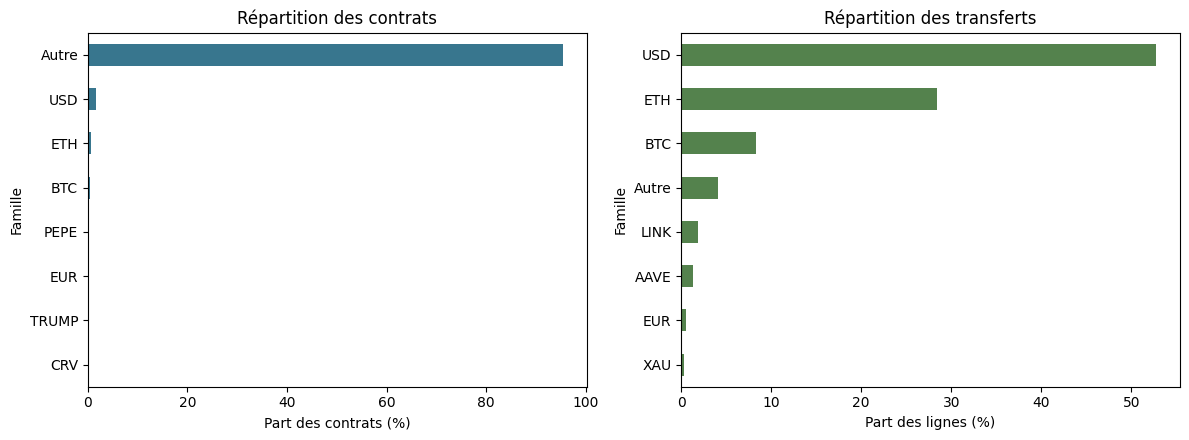

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
summary.nlargest(8, "n_tokens").sort_values("n_tokens")["share_tokens_pct"].plot.barh(
    ax=axes[0], color="#38768e"
)
axes[0].set(xlabel="Part des contrats (%)", ylabel="Famille", title="Répartition des contrats")
summary.head(8).sort_values("n_rows")["share_rows_pct"].plot.barh(
    ax=axes[1], color="#54824d"
)
axes[1].set(xlabel="Part des lignes (%)", ylabel="Famille", title="Répartition des transferts")
fig.tight_layout()
plt.show()

**Lecture des résultats.** Une famille est identifiée pour **599 contrats sur 13 087
(4,58 %)**, représentant **8 871 663 lignes (95,90 %)**. Parmi ces contrats, 344 sont
classés par adresse et 255 par nom.

**Autre** regroupe **12 488 contrats (95,42 %)** mais seulement **379 007 lignes (4,10 %)**.
Les contrats les plus fréquents expliquent cette différence. Ajouter l'étiquette Autre
change la présentation, pas le nombre de familles réellement identifiées.
La couverture atteint 99,93 % des lignes des transactions Aave et 90,98 % des autres
lignes tracées. Ces pourcentages ne mesurent pas la justesse des classements par nom.

USD arrive devant ETH puis BTC dans les fréquences de lignes. Cela ne prouve pas que
les wallets sont globalement longs ou shorts : ces comptages mélangent transferts,
reçus de dépôt et dettes, sans prix ni signe de position.

## 5. Voir la catégorie Autre et enregistrer la table de tokens

On peut examiner les tokens de la catégorie `Autre` par fréquence d'apparition.
Les classements acceptés par nom sont déjà dans leur famille et ne figurent pas ici.
Pour enrichir les règles plus tard, on pourra modifier les deux JSON et relancer le notebook.

On enregistre `data/token_families.parquet` : **une ligne par adresse de token**, avec
sa famille, son type, son statut et les comptages. Ce petit tableau sert de correspondance.

In [8]:
other = tokens.loc[tokens["family"].eq("Autre")].sort_values("n_rows", ascending=False)
display(other[["token_address", "token_symbol", "family", "n_rows"]].head(15))
tokens.to_parquet(DATA / "token_families.parquet", index=False)

,token_address,token_symbol,family,n_rows
55,0x0000000000a39bb272e79075ade125fd351887ac,Blur Pool,Autre,10747
85,0xe8ef806c8aadc541408dcad36107c7d26a391712,YT-eUSDE-14AUG2025,Autre,4743
96,0x029d6247adb0a57138c62e3019c92d3dfc9c1840,YT-sUSDE-25SEP2025,Autre,3921
105,0x59cd1c87501baa753d0b5b5ab5d8416a45cd71db,spWETH,Autre,3305
110,0x9fb7b4477576fe5b32be4c1843afb1e55f251b33,fUSDC,Autre,3076
112,0xc3d688b66703497daa19211eedff47f25384cdc3,cUSDCv3,Autre,3050
117,0x5c20b550819128074fd538edf79791733ccedd18,fUSDT,Autre,2679
128,0x48bbbedc4d2491cc08915d7a5c7cc8a8edf165da,YT-USDe-25SEP2025,Autre,2474
135,0xb7e51d15161c49c823f3951d579ded61cd27272b,YT-sUSDE-31JUL2025,Autre,2361
144,0x12b54025c112aa61face2cdb7118740875a566e9,spwstETH,Autre,2130


## 6. Produire le Parquet final des transferts

On reprend **toutes les lignes du fichier initial** et on ajoute trois colonnes :

- `family` : ETH, USD, BTC, une autre famille identifiée, ou `Autre` ;
- `token_kind` : le type de produit, par exemple un reçu de staking ou une dette ;
- `status` : l'origine du classement, par adresse ou par nom, ou l'absence de correspondance.

`classify_transfers` lit les transferts par lots, retrouve les étiquettes à partir de
`token_address` avec `map`, puis écrit `data/transfers_wallets_classified.parquet`.
Les colonnes initiales, leurs valeurs et l'ordre des lignes sont conservés.
Le fichier initial reste disponible ; une nouvelle exécution remplace le fichier de sortie.

Le tableau affiché ci-dessous est un extrait du **Parquet final réellement enregistré**.
Pour calculer des expositions ensuite, il restera à convertir les quantités, valoriser
les tokens et distinguer actifs et dettes. La famille seule ne suffit pas.

In [9]:
classify_transfers(INPUT, OUTPUT, tokens)

result = pq.ParquetFile(OUTPUT)
result_preview = next(result.iter_batches(batch_size=8)).to_pandas()
display(result_preview[["token_symbol", "value", "family", "token_kind", "status"]])
display(pd.DataFrame({
    "fichier": [INPUT.name, OUTPUT.name],
    "nombre_lignes": [parquet.metadata.num_rows, result.metadata.num_rows],
    "nombre_colonnes": [len(parquet.schema_arrow), len(result.schema_arrow)],
}))

,token_symbol,value,family,token_kind,status
0,aEthWETH,280679999999999999999,ETH,deposit_receipt,reference_match
1,ETH,280680000000000000000,ETH,native_and_wrapped,reference_match
2,aEthWETH,144756917947090285,ETH,deposit_receipt,reference_match
3,aEthWETH,280824756917947090284,ETH,deposit_receipt,reference_match
4,ETH,280824756917947090284,ETH,native_and_wrapped,reference_match
5,wstETH,227991825659069697488,ETH,staking_receipt,reference_match
6,ETH,280820000000000000000,ETH,native_and_wrapped,reference_match
7,wstETH,227991825659069697488,ETH,staking_receipt,reference_match


,fichier,nombre_lignes,nombre_colonnes
0,transfers_wallets_traced.parquet,9250670,13
1,transfers_wallets_classified.parquet,9250670,16
